# Analyse spatiale du risque d'inondation — Dakar

**Auteur :** E.A. Karim KEBE
**Cadre :** Travaux de recherche postdoctoraux — risques urbains à Dakar

Ce notebook combine un Modèle Numérique de Terrain (MNT) et des bandes spectrales
Sentinel-2 pour produire une carte de synthèse du risque d'inondation sur
l'agglomération de Dakar, en tenant compte de l'altitude ET de la présence
d'eau de surface détectée par télédétection.


## 1. Contexte et objectifs

Dakar, péninsule côtière densément urbanisée, est régulièrement exposée à des
inondations liées à la combinaison de fortes pluies, d'un relief globalement
plat et d'un réseau de drainage pluvial insuffisant. Une première approche de
cartographie du risque consiste à repérer les zones topographiquement basses à
partir d'un MNT. Cette approche seule est toutefois fragile : une dépression
topographique isolée, sans connexion hydrologique à une source d'eau, n'est
pas nécessairement inondable.

**Objectifs de ce notebook :**

1. Visualiser l'occupation du sol de Dakar en vraies couleurs.
2. Identifier les zones basses à partir du MNT (critère topographique).
3. Détecter l'eau de surface actuelle à partir de l'indice NDWI (critère
   spectral).
4. **Croiser les deux critères, spatialement alignés sur une même grille**, et
   filtrer les zones basses non connectées hydrologiquement à une source
   d'eau, afin de produire une carte de risque plus robuste que le simple
   seuillage altimétrique.
5. Discuter les limites de l'approche et les pistes d'amélioration.


## 2. Données utilisées

| Donnée | Fichier | Résolution | SCR | Source |
|---|---|---|---|---|
| Image vraies couleurs | `data/DAKAR VRAI COUEUR2.tif` | ~10 m | EPSG:4326 | Imagerie satellite (haute résolution) |
| Modèle Numérique de Terrain | `data/Dakar_MNE_5m.tif` | 5 m | EPSG:32628 (UTM 28N) | MNT Dakar |
| Bande Verte (Sentinel-2, B3) | `data/b32.tif` | ~10 m | EPSG:4326 | Sentinel-2 |
| Bande Proche Infrarouge (Sentinel-2, B8) | `data/b82.tif` | ~10 m | EPSG:4326 | Sentinel-2 |

Les fichiers raster ne sont **pas** versionnés dans ce dépôt (ils dépassent la
limite de taille de GitHub) : voir le `README.md` pour les récupérer et les
placer dans `data/`.


In [1]:
# --- Imports et constantes ---
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import reproject
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
from scipy import ndimage

# Dossiers du projet (chemins relatifs : le notebook est portable sur toute machine)
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

TRUE_COLOR_PATH = DATA_DIR / "DAKAR VRAI COUEUR2.tif"
DEM_PATH = DATA_DIR / "Dakar_MNE_5m.tif"
GREEN_PATH = DATA_DIR / "b32.tif"   # bande verte (Sentinel-2 B3)
NIR_PATH = DATA_DIR / "b82.tif"     # bande proche infrarouge (Sentinel-2 B8)

# Seuils de classification (en mètres) — à calibrer avec des données de terrain si disponibles
SEUIL_INONDABLE = 5   # altitude sous laquelle une zone est considérée potentiellement inondable
SEUIL_INONDEE = 2     # altitude sous laquelle une zone est considérée très exposée / déjà inondée
SEUIL_NDWI_EAU = 0.0  # seuil classique NDWI > 0 => eau de surface


## 3. Image en vraies couleurs

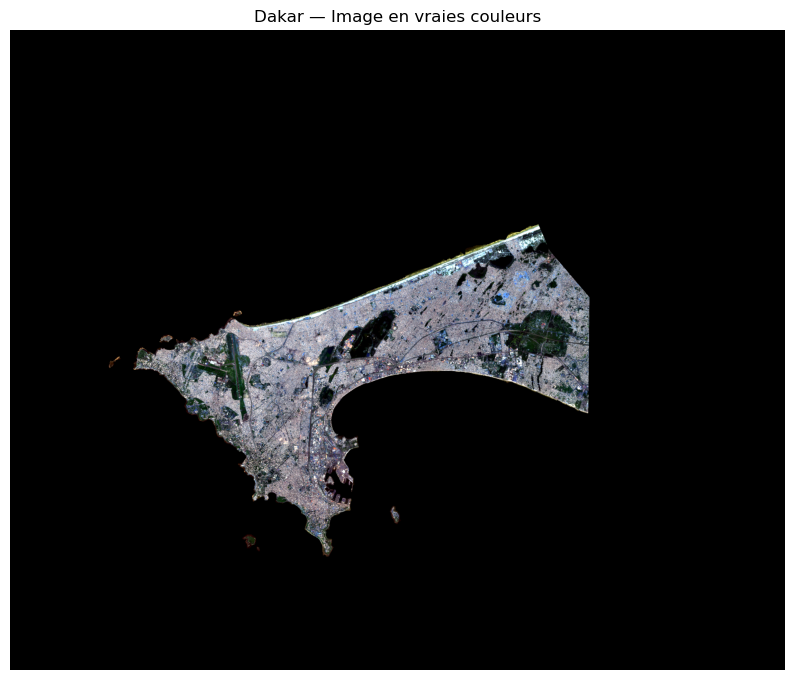

In [2]:
def charger_rgb_normalise(path):
    # Charge les 3 premières bandes d'un GeoTIFF et les normalise en [0, 1]
    with rasterio.open(path) as src:
        bandes = src.read([1, 2, 3]).astype(float)
        nodata = src.nodata
    if nodata is not None:
        bandes[bandes == nodata] = np.nan
    for i in range(3):
        bande = bandes[i]
        # Étirement de contraste par percentiles (2-98%) : plus robuste aux
        # valeurs extrêmes isolées qu'une simple division par le maximum.
        p2, p98 = np.nanpercentile(bande, [2, 98])
        if p98 > p2:
            bandes[i] = (bande - p2) / (p98 - p2)
    rgb = np.nan_to_num(np.dstack(bandes), nan=0.0)
    return np.clip(rgb, 0, 1)


rgb = charger_rgb_normalise(TRUE_COLOR_PATH)

plt.figure(figsize=(10, 10))
plt.imshow(rgb)
plt.title("Dakar — Image en vraies couleurs")
plt.axis("off")
plt.savefig(OUTPUT_DIR / "01_vraies_couleurs.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Modèle Numérique de Terrain (MNT) : zones basses

In [3]:
with rasterio.open(DEM_PATH) as src:
    dem = src.read(1).astype(float)
    dem[dem == src.nodata] = np.nan
    dem_transform = src.transform
    dem_crs = src.crs
    dem_profile = src.profile

print(f"Dimensions du MNT : {dem.shape}")
print(f"SCR du MNT : {dem_crs}")
print(f"Altitude min/max : {np.nanmin(dem):.1f} m / {np.nanmax(dem):.1f} m")

# --- Contrôle qualité : valeur de remplissage à 0 m ---
# Un MNT de terrain ne produit normalement jamais exactement 0.000000 m sur des
# millions de pixels indépendants : une telle répétition signale une valeur de
# remplissage conventionnelle (mer / lacune de la mosaïque), pas un relief réel.
part_zero = float(np.isclose(dem, 0.0).mean()) * 100
print(f"Part des pixels valides exactement à 0 m : {part_zero:.1f} % "
      "(valeur de remplissage probable : mer ou lacune du MNT, traitée comme donnée manquante ci-dessous)")
dem[np.isclose(dem, 0.0)] = np.nan


Dimensions du MNT : (3697, 5088)
SCR du MNT : EPSG:32628
Altitude min/max : -10.7 m / 104.0 m
Part des pixels valides exactement à 0 m : 27.4 % (valeur de remplissage probable : mer ou lacune du MNT, traitée comme donnée manquante ci-dessous)


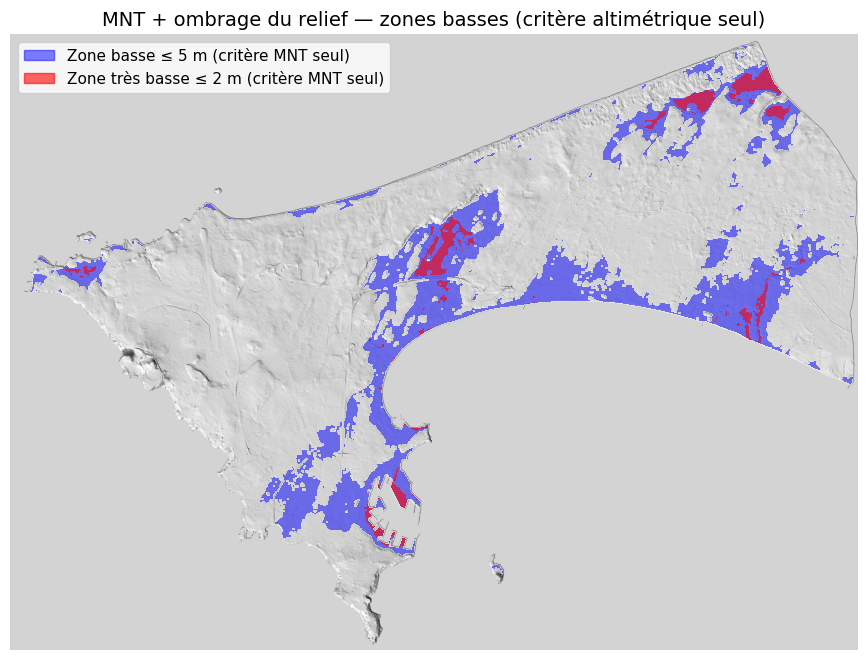

In [4]:
def hillshade(dem_array, azimuth=315, altitude=45):
    # Calcule un ombrage simple du relief pour la mise en contexte cartographique
    x, y = np.gradient(dem_array)
    slope = np.pi / 2 - np.arctan(np.sqrt(x * x + y * y))
    aspect = np.arctan2(-x, y)
    az = np.radians(360 - azimuth)
    alt = np.radians(altitude)
    shaded = np.sin(alt) * np.sin(slope) + np.cos(alt) * np.cos(slope) * np.cos(az - aspect)
    return shaded


dem_filled = np.nan_to_num(dem, nan=np.nanmin(dem))
shaded = hillshade(dem_filled)

zones_inondables = dem <= SEUIL_INONDABLE
zones_inondees = dem <= SEUIL_INONDEE

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(shaded, cmap="gray")
ax.imshow(np.where(zones_inondables, 1, np.nan), cmap=ListedColormap(["blue"]), alpha=0.5)
ax.imshow(np.where(zones_inondees, 1, np.nan), cmap=ListedColormap(["red"]), alpha=0.6)

patches = [
    mpatches.Patch(color="blue", alpha=0.5, label=f"Zone basse ≤ {SEUIL_INONDABLE} m (critère MNT seul)"),
    mpatches.Patch(color="red", alpha=0.6, label=f"Zone très basse ≤ {SEUIL_INONDEE} m (critère MNT seul)"),
]
ax.legend(handles=patches, fontsize=11, loc="upper left")
ax.set_title("MNT + ombrage du relief — zones basses (critère altimétrique seul)", fontsize=14)
ax.axis("off")
plt.savefig(OUTPUT_DIR / "02_mnt_zones_basses.png", dpi=150, bbox_inches="tight")
plt.show()


## 5. Indice d'eau NDWI (Sentinel-2)

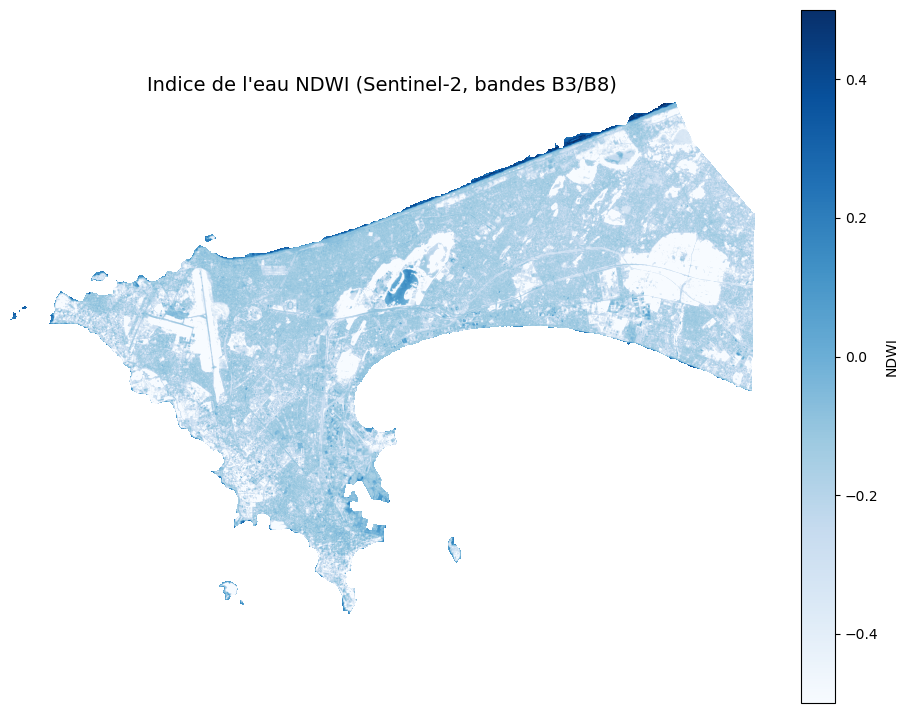

In [5]:
with rasterio.open(GREEN_PATH) as src:
    green = src.read(1).astype(float)
    green[green == src.nodata] = np.nan
    optical_transform = src.transform
    optical_crs = src.crs
    optical_shape = src.shape

with rasterio.open(NIR_PATH) as src:
    nir = src.read(1).astype(float)
    nir[nir == src.nodata] = np.nan

ndwi = (green - nir) / (green + nir + 1e-10)

plt.figure(figsize=(12, 9), facecolor="white")
im = plt.imshow(ndwi, cmap="Blues", vmin=-0.5, vmax=0.5)
plt.colorbar(im, label="NDWI")
plt.title("Indice de l'eau NDWI (Sentinel-2, bandes B3/B8)", fontsize=14)
plt.axis("off")
plt.savefig(OUTPUT_DIR / "03_ndwi.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Carte de synthèse du risque — alignement spatial et connectivité hydrologique

Le MNT (UTM 28N, 5 m) et les bandes Sentinel-2 (EPSG:4326, ~10 m) ne partagent
pas la même grille. Les superposer sans reprojection, comme dans une première
version de ce travail, produit des cartes juxtaposées mais pas une véritable
fusion pixel à pixel.

Ici, le MNT est **ré-échantillonné sur la grille des bandes Sentinel-2**
(`rasterio.warp.reproject`, interpolation bilinéaire), ce qui permet de croiser
réellement les deux critères.

De plus, un seuil altimétrique seul classe comme « inondable » toute dépression
topographique, même si elle n'est reliée à aucune source d'eau. On applique un
filtre de **connectivité hydrologique** (étiquetage des composantes connexes,
`scipy.ndimage.label`) qui ne conserve une zone basse que si elle touche soit
une zone d'eau détectée par NDWI, soit le bord de la zone d'étude (proxy d'une
connexion vers l'océan ou un cours d'eau sortant de l'emprise analysée).

**Contrôle qualité réalisé sur le MNT :** l'inspection du MNT (section 4)
montre qu'une proportion importante des pixels valides vaut exactement
`0.000000 m`, ce qui n'arrive jamais sur un relief réel mesuré — c'est le
signe d'une valeur de remplissage conventionnelle (mer, ou lacune de la
mosaïque du MNT). Si on ne la traite pas, cette valeur de remplissage est
automatiquement classée « zone très exposée », ce qui gonfle artificiellement
les surfaces à risque. Ces pixels sont donc convertis en donnée manquante
avant toute classification.


In [6]:
# --- Reprojection du MNT sur la grille Sentinel-2 ---
# GDAL gère mal un nodata flottant NaN lors du warp (les pixels hors emprise
# source peuvent être remplis à 0 au lieu de NaN) : on repasse par un nodata
# numérique classique, puis on reconvertit en NaN après coup.
NODATA_REPROJ = -9999.0
dem_pour_reprojection = np.where(np.isfinite(dem), dem, NODATA_REPROJ)

dem_aligned = np.full(optical_shape, NODATA_REPROJ, dtype=float)
reproject(
    source=dem_pour_reprojection,
    destination=dem_aligned,
    src_transform=dem_transform,
    src_crs=dem_crs,
    src_nodata=NODATA_REPROJ,
    dst_transform=optical_transform,
    dst_crs=optical_crs,
    dst_nodata=NODATA_REPROJ,
    resampling=Resampling.bilinear,
)
dem_aligned[dem_aligned == NODATA_REPROJ] = np.nan

couverture = np.isfinite(dem_aligned).mean() * 100
print(f"Couverture du MNT sur l'emprise Sentinel-2 après reprojection : {couverture:.1f} %")


Couverture du MNT sur l'emprise Sentinel-2 après reprojection : 34.0 %


In [7]:
# --- Classification croisée MNT + NDWI avec filtre de connectivité ---
eau_ndwi = ndwi > SEUIL_NDWI_EAU
basse_altitude = dem_aligned <= SEUIL_INONDABLE
tres_basse_altitude = dem_aligned <= SEUIL_INONDEE

# Composantes connexes des zones basses (connectivité à 8 voisins)
structure = np.ones((3, 3))
etiquettes, nb_composantes = ndimage.label(basse_altitude, structure=structure)

# Bord de l'emprise = proxy d'une connexion hydrologique sortant de la zone d'étude
bord = np.zeros_like(basse_altitude, dtype=bool)
bord[0, :] = bord[-1, :] = bord[:, 0] = bord[:, -1] = True

composantes_connectees = set(np.unique(etiquettes[eau_ndwi & basse_altitude]))
composantes_connectees |= set(np.unique(etiquettes[bord & basse_altitude]))
composantes_connectees.discard(0)

basse_connectee = np.isin(etiquettes, list(composantes_connectees))

print(f"Composantes de zones basses détectées : {nb_composantes}")
print(f"Composantes retenues après filtre de connectivité : {len(composantes_connectees)}")
print(f"Surface 'inondable' avant filtre : {basse_altitude.sum()} pixels")
print(f"Surface 'inondable' après filtre de connectivité : {basse_connectee.sum()} pixels")


Composantes de zones basses détectées : 441
Composantes retenues après filtre de connectivité : 76
Surface 'inondable' avant filtre : 456466 pixels
Surface 'inondable' après filtre de connectivité : 439808 pixels


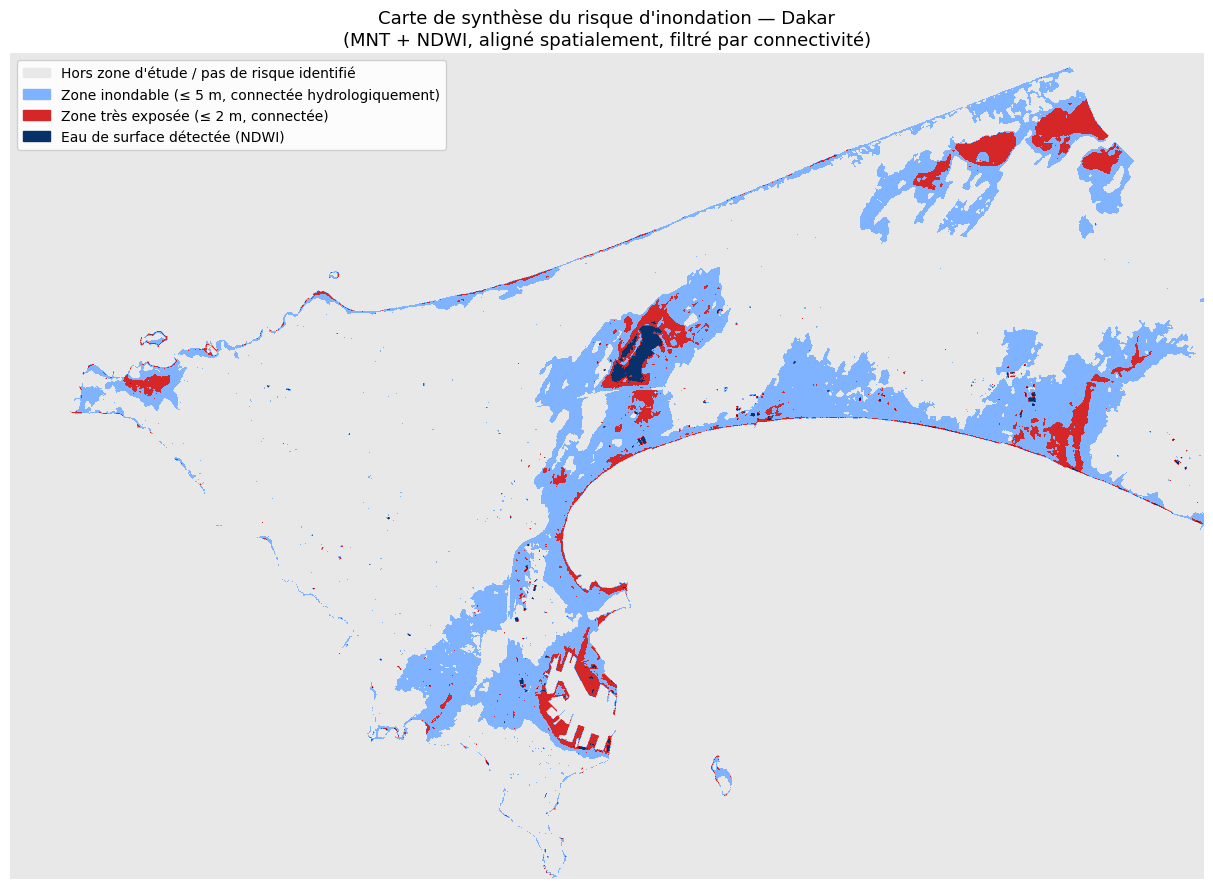

In [8]:
# --- Carte de synthèse (4 classes) ---
# 0 = aucun risque identifié, 1 = inondable (connecté), 2 = très exposé (connecté), 3 = eau de surface (NDWI)
classes = np.zeros(optical_shape, dtype=np.uint8)
classes[basse_connectee] = 1
classes[basse_connectee & (tres_basse_altitude)] = 2
classes[eau_ndwi] = 3
classes[~np.isfinite(dem_aligned)] = 0

couleurs = ["#e8e8e8", "#7fb3ff", "#d62728", "#08306b"]
labels = [
    "Hors zone d'étude / pas de risque identifié",
    f"Zone inondable (≤ {SEUIL_INONDABLE} m, connectée hydrologiquement)",
    f"Zone très exposée (≤ {SEUIL_INONDEE} m, connectée)",
    "Eau de surface détectée (NDWI)",
]
cmap = ListedColormap(couleurs)
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap.N)

fig, ax = plt.subplots(figsize=(13, 9), facecolor="white")
ax.imshow(classes, cmap=cmap, norm=norm)
patches = [mpatches.Patch(color=couleurs[i], label=labels[i]) for i in range(4)]
ax.legend(handles=patches, fontsize=10, loc="upper left", framealpha=0.9)
ax.set_title("Carte de synthèse du risque d'inondation — Dakar\n(MNT + NDWI, aligné spatialement, filtré par connectivité)", fontsize=13)
ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_carte_synthese_risque.png", dpi=150, bbox_inches="tight")
plt.show()


## 7. Vue d'ensemble : les quatre couches

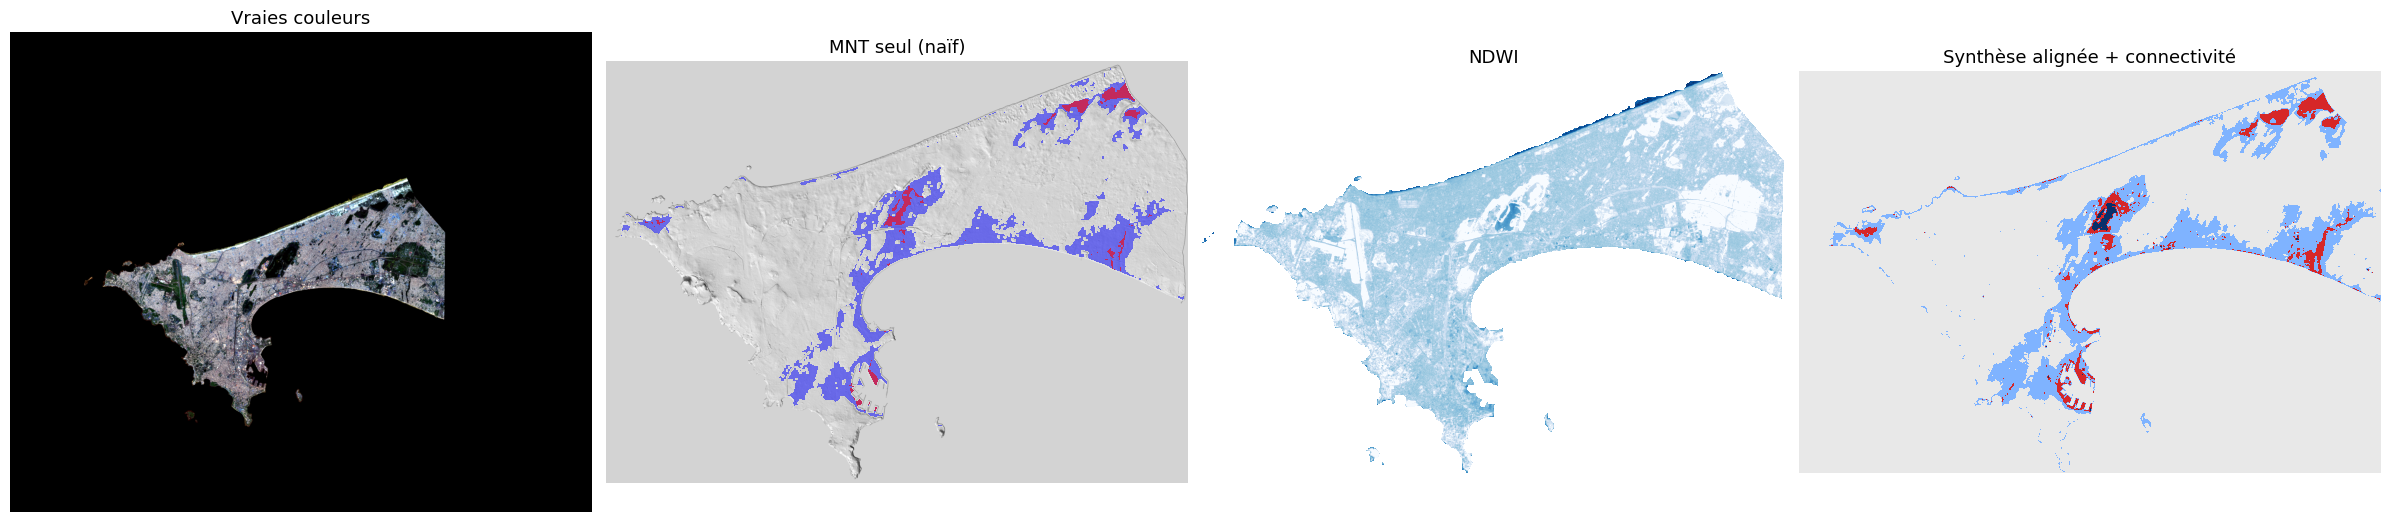

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(24, 7), facecolor="white")

axes[0].imshow(rgb)
axes[0].set_title("Vraies couleurs", fontsize=13)
axes[0].axis("off")

axes[1].imshow(shaded, cmap="gray")
axes[1].imshow(np.where(zones_inondables, 1, np.nan), cmap=ListedColormap(["blue"]), alpha=0.5)
axes[1].imshow(np.where(zones_inondees, 1, np.nan), cmap=ListedColormap(["red"]), alpha=0.6)
axes[1].set_title("MNT seul (naïf)", fontsize=13)
axes[1].axis("off")

im_ndwi = axes[2].imshow(ndwi, cmap="Blues", vmin=-0.5, vmax=0.5)
axes[2].set_title("NDWI", fontsize=13)
axes[2].axis("off")

axes[3].imshow(classes, cmap=cmap, norm=norm)
axes[3].set_title("Synthèse alignée + connectivité", fontsize=13)
axes[3].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_vue_ensemble.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. Limites et perspectives

- **Seuils fixes (5 m / 2 m / NDWI > 0)** : choisis par défaut, à calibrer avec
  des relevés de terrain, des données de précipitations ou des épisodes
  d'inondation historiques documentés.
- **Proxy de connectivité simplifié** : le filtre retenu utilise le bord de
  l'image et l'eau NDWI comme sources ; un modèle hydrologique complet
  (direction d'écoulement, accumulation de flux, réseau de drainage réel)
  donnerait une délimitation plus précise.
- **Image vraies couleurs non reprojetée** : conservée à sa résolution native
  pour la visualisation, mais non intégrée dans la classification croisée.
- **Validation** : aucune confrontation avec des données de vulnérabilité
  (population, bâti, infrastructures) ou des inondations observées n'est
  encore réalisée — étape logique de poursuite de ce travail.

## 9. Conclusion

Ce notebook montre qu'une carte de risque d'inondation basée sur un seul
critère altimétrique surestime les zones à risque. En alignant spatialement
le MNT et l'indice NDWI puis en appliquant un filtre de connectivité
hydrologique, on obtient une carte de synthèse plus défendable
scientifiquement, tout en documentant explicitement ses limites et les pistes
d'amélioration (calibration des seuils, modélisation hydrologique complète,
croisement avec des données de vulnérabilité).
